# SVM — Effect of C and Kernel Choice

`make_moons` data: decision boundaries and support vectors for C from 0.05 to 100, then linear vs. polynomial vs. RBF vs. sigmoid kernels.

# (a)

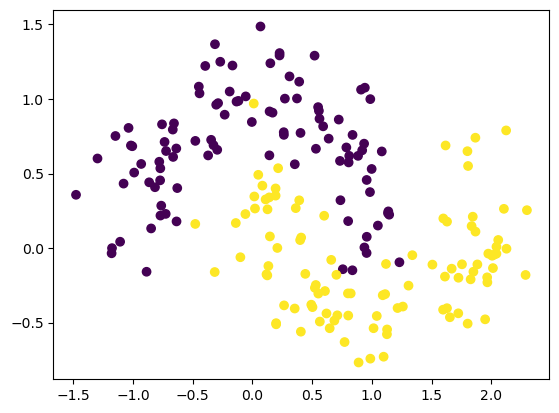

In [4]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.2, random_state=42)

plt.scatter(X[:,0], X[:,1], c=y)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# (b)

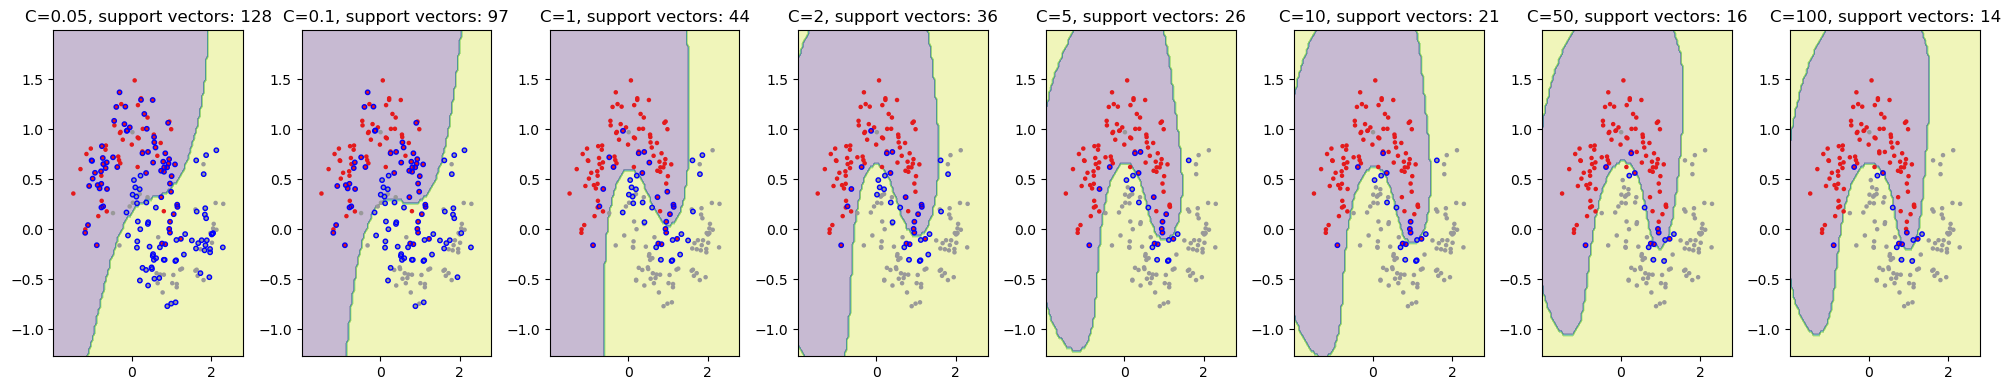

In [5]:
from sklearn.svm import SVC
import numpy as np

C_values = [0.05, 0.1, 1, 2, 5, 10, 50, 100]

fig, axes = plt.subplots(1, len(C_values), figsize=(20, 4))

for i, C in enumerate(C_values):
    
    svm = SVC(kernel='rbf', C=C, gamma='scale', random_state=42)
    svm.fit(X_train, y_train)
    
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))
    
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    axes[i].contourf(xx, yy, Z, alpha=0.3)
    
    axes[i].scatter(X[:, 0], X[:, 1], c=y, s=5, cmap=plt.cm.Set1)
    
    axes[i].scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1], 
                   s=10, facecolors='none', edgecolors='blue')
    
    axes[i].set_title(f'C={C}, support vectors: {len(svm.support_vectors_)}')
    axes[i].set_xlim(x_min, x_max)
    axes[i].set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

### The presence of C affects the power of the model. The larger the C value, the stronger the model power, and the more likely it is to overfit. From the graph, it can be seen that when C is greater than 1, the model exhibits significant overfitting. In addition, the larger the C value, the fewer the number of support vectors will be.

# (c)

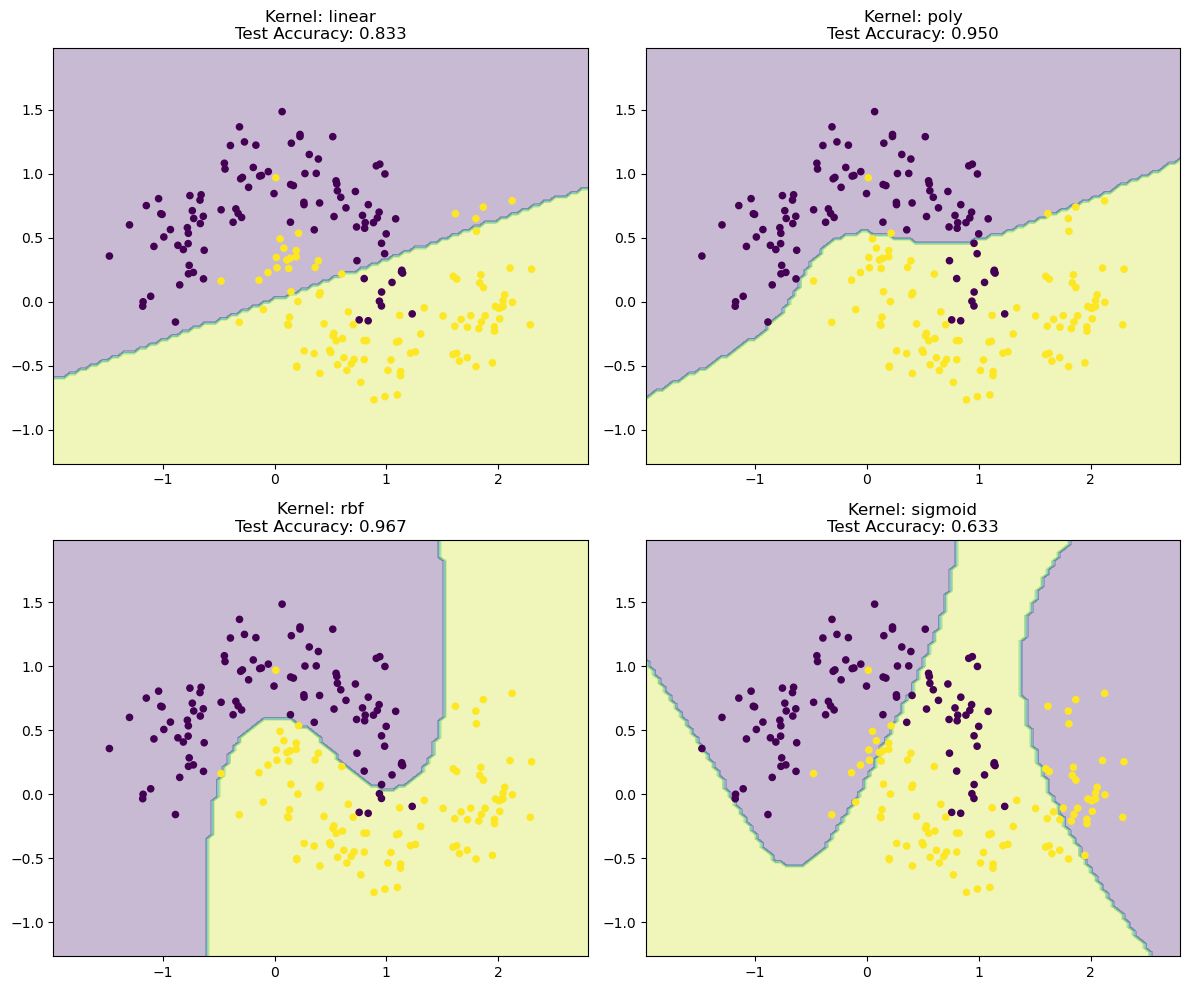

In [6]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
from sklearn.metrics import accuracy_score

test_accuracies = []

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, kernel in enumerate(kernels):
    
    if kernel == 'poly':
        svm = SVC(kernel=kernel, C=1, gamma='scale', degree=3)
    else:
        svm = SVC(kernel=kernel, C=1, gamma='scale')
    
    svm.fit(X_train, y_train)
    
    y_pred = svm.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    test_accuracies.append(accuracy)
    
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))
    
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    axes[i].contourf(xx, yy, Z, alpha=0.3)
    
    axes[i].scatter(X[:, 0], X[:, 1], c=y, s=20)
    
    axes[i].set_title(f'Kernel: {kernel}\nTest Accuracy: {accuracy:.3f}')

plt.tight_layout()
plt.show()

### RBF gives the Best performance on the test dataset.